# PROGETTO FINALE M5

🍽️ ChefBot AI – Dallo scatto alla ricetta

Progetto finale del Modulo 5 del corso Python, AI e Machine Learning di EPICODE.

ChefBot AI è un sistema intelligente che combina Computer Vision e Natural Language Processing 
per riconoscere piatti alimentari attraverso fotografie e fornire informazioni su ingredienti, calorie stimate e descrizioni.

Il progetto utilizza MobileNetV2 con Transfer Learning, il dataset Food101 e un database JSON per le informazioni alimentari.

Include inoltre una funzione di ricerca semantica basata su embeddings e similarità coseno, che suggerisce 
piatti in base alle preferenze espresse dall'utente in linguaggio naturale.

In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds

SEED = 42
tf.keras.utils.set_random_seed(SEED)

classi_scelte = [
    "apple_pie",
    "baklava",
    "caesar_salad",
    "cheesecake",
    "chicken_curry",
    "chocolate_cake",
    "churros",
    "club_sandwich",
    "french_fries",
    "greek_salad",
    "hamburger",
    "ice_cream",
    "pizza",
    "ramen",
    "sushi"
]

NUM_CLASSI = len(classi_scelte)

builder = tfds.builder("food101")
info = builder.info

classi_originali = info.features["label"].names

assert NUM_CLASSI == 15
assert all(nome in classi_originali for nome in classi_scelte)

indici_originali = [
    info.features["label"].str2int(nome)
    for nome in classi_scelte
]

print("Dataset: Food101")
print("Classi originali:", len(classi_originali))
print("Classi selezionate:", NUM_CLASSI)

for indice, nome in enumerate(classi_scelte):
    print(f"{indice}: {nome}")

Dataset: Food101
Classi originali: 101
Classi selezionate: 15
0: apple_pie
1: baklava
2: caesar_salad
3: cheesecake
4: chicken_curry
5: chocolate_cake
6: churros
7: club_sandwich
8: french_fries
9: greek_salad
10: hamburger
11: ice_cream
12: pizza
13: ramen
14: sushi


In [2]:
from pathlib import Path
from torchvision.datasets import Food101

cartella_estratti = Path.home() / "tensorflow_datasets" / "downloads" / "extracted"

cartelle = [
    p for p in cartella_estratti.glob("*/food-101")
    if (p / "images").is_dir()
    and (p / "meta" / "train.json").is_file()
    and (p / "meta" / "test.json").is_file()
]

if not cartelle:
    raise FileNotFoundError("Dataset Food101 estratto non trovato.")

cartella_food101 = cartelle[0]

ds_train_originale = Food101(
    root=cartella_food101.parent,
    split="train",
    download=False
)

ds_test_originale = Food101(
    root=cartella_food101.parent,
    split="test",
    download=False
)

mappa_etichette = {
    ds_train_originale.class_to_idx[nome]: indice
    for indice, nome in enumerate(classi_scelte)
}

indici_train = [
    i for i, etichetta in enumerate(ds_train_originale._labels)
    if etichetta in mappa_etichette
]

indici_test = [
    i for i, etichetta in enumerate(ds_test_originale._labels)
    if etichetta in mappa_etichette
]

file_mancanti = [
    str(percorso)
    for dataset, indici in [
        (ds_train_originale, indici_train),
        (ds_test_originale, indici_test)
    ]
    for indice in indici
    if not dataset._image_files[indice].is_file()
]

print("Dataset: Food101")
print("Classi selezionate:", NUM_CLASSI)
print("Immagini training:", len(indici_train))
print("Immagini test:", len(indici_test))
print("File mancanti:", len(file_mancanti))

assert len(indici_train) == 11250
assert len(indici_test) == 3750
assert not file_mancanti, "Alcune immagini risultano mancanti."

Dataset: Food101
Classi selezionate: 15
Immagini training: 11250
Immagini test: 3750
File mancanti: 0


In [3]:
from sklearn.model_selection import train_test_split

percorsi_train_completi = [
    str(ds_train_originale._image_files[i])
    for i in indici_train
]

etichette_train_complete = [
    mappa_etichette[ds_train_originale._labels[i]]
    for i in indici_train
]

percorsi_test = [
    str(ds_test_originale._image_files[i])
    for i in indici_test
]

etichette_test = [
    mappa_etichette[ds_test_originale._labels[i]]
    for i in indici_test
]

percorsi_train, percorsi_val, etichette_train, etichette_val = train_test_split(
    percorsi_train_completi,
    etichette_train_complete,
    test_size=0.20,
    random_state=SEED,
    stratify=etichette_train_complete
)

print("Training:", len(percorsi_train))
print("Validation:", len(percorsi_val))
print("Test:", len(percorsi_test))
print("Totale immagini:", len(percorsi_train) + len(percorsi_val) + len(percorsi_test))

Training: 9000
Validation: 2250
Test: 3750
Totale immagini: 15000


In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def prepara_immagine(percorso, etichetta):
    immagine = tf.io.read_file(percorso)
    immagine = tf.image.decode_jpeg(immagine, channels=3)
    immagine = tf.image.resize(immagine, IMG_SIZE)
    immagine = tf.keras.applications.mobilenet_v2.preprocess_input(immagine)

    return immagine, etichetta

def crea_dataset(percorsi, etichette, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (percorsi, etichette)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        prepara_immagine,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset

ds_train = crea_dataset(
    percorsi_train,
    etichette_train,
    training=True
)

ds_val = crea_dataset(
    percorsi_val,
    etichette_val
)

ds_test = crea_dataset(
    percorsi_test,
    etichette_test
)

immagini, etichette = next(iter(ds_train.take(1)))

print("Dimensioni batch immagini:", immagini.shape)
print("Dimensioni batch etichette:", etichette.shape)
print("Tipo dati:", immagini.dtype)
print("Dataset pronti per MobileNetV2")

Dimensioni batch immagini: (16, 224, 224, 3)
Dimensioni batch etichette: (16,)
Tipo dati: <dtype: 'float32'>
Dataset pronti per MobileNetV2


In [5]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSI,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ChefBot_AI"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("\nClassi riconoscibili:", NUM_CLASSI)
print("Base pre-addestrata congelata:", not base_model.trainable)
print("Parametri addestrabili:", model.count_params() - sum(
    tf.keras.backend.count_params(p)
    for p in model.non_trainable_weights
))

Model: "ChefBot_AI"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Classi riconoscibili: 15
Base pre-addestrata congelata: True
Parametri addestrabili: 19215


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="chefbot_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=6,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

print("\nAddestramento prima fase completato")
print("Epoche eseguite:", len(history.history["loss"]))
print("Migliore validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

Epoch 1/6


c:\Users\andri\tensorflow313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6593 - loss: 1.0934
Epoch 1: val_loss improved from None to 0.72730, saving model to chefbot_mobilenetv2.keras

Epoch 1: finished saving model to chefbot_mobilenetv2.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 68s 116ms/step - accuracy: 0.6593 - loss: 1.0934 - val_accuracy: 0.7729 - val_loss: 0.7273
Epoch 2/6
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7787 - loss: 0.6903
Epoch 2: val_loss improved from 0.72730 to 0.65195, saving model to chefbot_mobilenetv2.keras

Epoch 2: finished saving model to chefbot_mobilenetv2.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 60s 106ms/step - accuracy: 0.7788 - loss: 0.6899 - val_accuracy: 0.7951 - val_loss: 0.6519
Epoch 3/6
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8098 - loss: 0.5844
Epoch 3: val_loss did not improve from 0.65195
563/563 ━━━━━━━━━━━━━━━━━━━━ 60s 107ms/step - accuracy: 0.8098 - loss: 0.5843 - val_accuracy: 0.7973 - val_loss: 0.6574
Epoch 4/6
562/563 ━━━━━━━━━━━━━━━━━━━━

In [7]:
test_loss, test_accuracy = model.evaluate(
    ds_test,
    verbose=1
)

print("\nVALUTAZIONE CHEFBOT AI")
print(f"Immagini di test: {len(percorsi_test)}")
print(f"Classi riconosciute: {NUM_CLASSI}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.8323 - loss: 0.5205

VALUTAZIONE CHEFBOT AI
Immagini di test: 3750
Classi riconosciute: 15
Test Accuracy: 83.23%
Test Loss: 0.5205


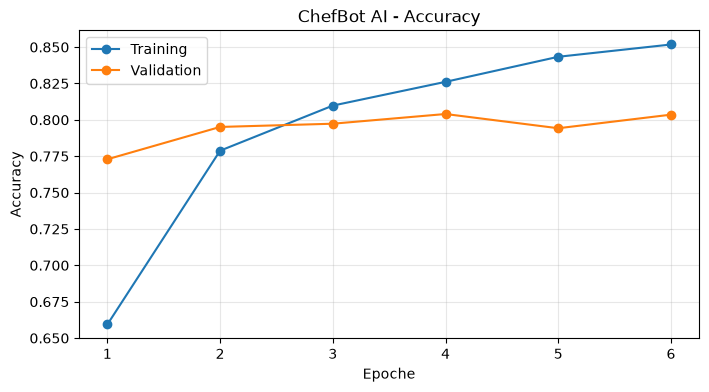

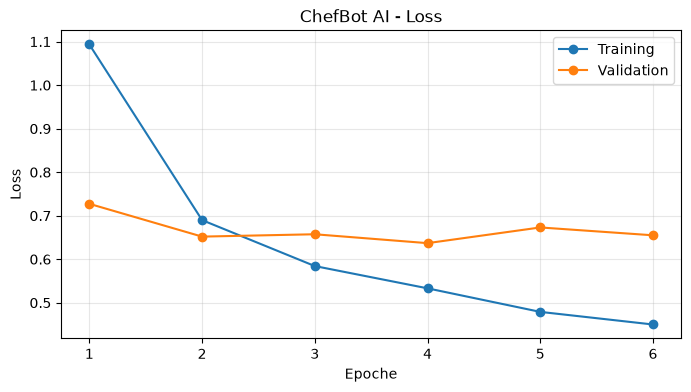

In [8]:
import matplotlib.pyplot as plt

epoche = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epoche, history.history["accuracy"], marker="o", label="Training")
plt.plot(epoche, history.history["val_accuracy"], marker="o", label="Validation")
plt.title("ChefBot AI - Accuracy")
plt.xlabel("Epoche")
plt.ylabel("Accuracy")
plt.xticks(list(epoche))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epoche, history.history["loss"], marker="o", label="Training")
plt.plot(epoche, history.history["val_loss"], marker="o", label="Validation")
plt.title("ChefBot AI - Loss")
plt.xlabel("Epoche")
plt.ylabel("Loss")
plt.xticks(list(epoche))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
from pathlib import Path

assert Path("chefbot_mobilenetv2.keras").is_file(), "Modello iniziale non trovato."

base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers[-20:]:
    layer.trainable = not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

parametri_addestrabili = sum(
    int(tf.size(p)) for p in model.trainable_weights
)

print("Fine-Tuning configurato correttamente")
print("Livelli totali MobileNetV2:", len(base_model.layers))
print("Livelli addestrabili:", sum(layer.trainable for layer in base_model.layers))
print("Parametri addestrabili:", parametri_addestrabili)
print("Learning rate:", 0.00001)

Fine-Tuning configurato correttamente
Livelli totali MobileNetV2: 154
Livelli addestrabili: 13
Parametri addestrabili: 1214095
Learning rate: 1e-05


In [10]:
early_stopping_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint_ft = tf.keras.callbacks.ModelCheckpoint(
    filepath="chefbot_mobilenetv2_finetuned.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_ft = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=4,
    callbacks=[early_stopping_ft, checkpoint_ft],
    verbose=1
)

print("\nFINE-TUNING COMPLETATO")
print("Epoche eseguite:", len(history_ft.history["loss"]))

print(
    "Migliore Validation Accuracy:",
    f"{max(history_ft.history['val_accuracy']) * 100:.2f}%"
)

print(
    "Migliore Validation Loss:",
    f"{min(history_ft.history['val_loss']):.4f}"
)

Epoch 1/4
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.8591 - loss: 0.4284
Epoch 1: val_loss improved from None to 0.63137, saving model to chefbot_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to chefbot_mobilenetv2_finetuned.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 79s 135ms/step - accuracy: 0.8591 - loss: 0.4284 - val_accuracy: 0.8058 - val_loss: 0.6314
Epoch 2/4
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.8823 - loss: 0.3670
Epoch 2: val_loss improved from 0.63137 to 0.61460, saving model to chefbot_mobilenetv2_finetuned.keras

Epoch 2: finished saving model to chefbot_mobilenetv2_finetuned.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 76s 135ms/step - accuracy: 0.8823 - loss: 0.3670 - val_accuracy: 0.8089 - val_loss: 0.6146
Epoch 3/4
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8981 - loss: 0.3159
Epoch 3: val_loss improved from 0.61460 to 0.61125, saving model to chefbot_mobilenetv2_finetuned.keras

Epoch 3: finished saving model to chefbot_mobil

In [11]:
model = tf.keras.models.load_model(
    "chefbot_mobilenetv2_finetuned.keras"
)

test_loss_ft, test_accuracy_ft = model.evaluate(
    ds_test,
    verbose=1
)

print("\nVALUTAZIONE FINALE CHEFBOT AI")
print(f"Immagini di test: {len(percorsi_test)}")
print(f"Classi riconosciute: {NUM_CLASSI}")
print(f"Test Accuracy iniziale: {test_accuracy * 100:.2f}%")
print(f"Test Accuracy Fine-Tuned: {test_accuracy_ft * 100:.2f}%")
print(f"Test Loss Fine-Tuned: {test_loss_ft:.4f}")

235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 86ms/step - accuracy: 0.8469 - loss: 0.4823

VALUTAZIONE FINALE CHEFBOT AI
Immagini di test: 3750
Classi riconosciute: 15
Test Accuracy iniziale: 83.23%
Test Accuracy Fine-Tuned: 84.69%
Test Loss Fine-Tuned: 0.4823


In [12]:
import json

dati_piatti = {
    "apple_pie": {
        "ingredienti": ["mele", "farina", "burro", "zucchero", "cannella"],
        "porzione": "150 g",
        "calorie_stimate_kcal": 350,
        "descrizione": "Torta dolce alle mele, speziata con cannella e cotta al forno."
    },
    "baklava": {
        "ingredienti": ["pasta fillo", "noci", "pistacchi", "miele", "burro"],
        "porzione": "90 g",
        "calorie_stimate_kcal": 390,
        "descrizione": "Dolce croccante e molto dolce, con frutta secca e sciroppo al miele."
    },
    "caesar_salad": {
        "ingredienti": ["lattuga", "crostini", "parmigiano", "salsa Caesar"],
        "porzione": "300 g",
        "calorie_stimate_kcal": 480,
        "descrizione": "Insalata fresca con lattuga croccante, formaggio e condimento cremoso."
    },
    "cheesecake": {
        "ingredienti": ["formaggio cremoso", "biscotti", "burro", "zucchero"],
        "porzione": "130 g",
        "calorie_stimate_kcal": 420,
        "descrizione": "Dessert dolce e cremoso a base di formaggio e biscotti."
    },
    "chicken_curry": {
        "ingredienti": ["pollo", "curry", "cipolla", "pomodoro", "olio"],
        "porzione": "300 g",
        "calorie_stimate_kcal": 460,
        "descrizione": "Piatto caldo e speziato a base di pollo e salsa aromatica."
    },
    "chocolate_cake": {
        "ingredienti": ["cioccolato", "farina", "uova", "burro", "zucchero"],
        "porzione": "130 g",
        "calorie_stimate_kcal": 480,
        "descrizione": "Torta ricca e golosa al cioccolato, ideale come dessert."
    },
    "churros": {
        "ingredienti": ["farina", "acqua", "olio", "zucchero", "cannella"],
        "porzione": "100 g",
        "calorie_stimate_kcal": 400,
        "descrizione": "Dolce fritto croccante, spesso servito con zucchero o cioccolato."
    },
    "club_sandwich": {
        "ingredienti": ["pane", "pollo", "bacon", "lattuga", "pomodoro", "maionese"],
        "porzione": "250 g",
        "calorie_stimate_kcal": 520,
        "descrizione": "Sandwich salato a più strati con carne, verdure e salsa."
    },
    "french_fries": {
        "ingredienti": ["patate", "olio", "sale"],
        "porzione": "150 g",
        "calorie_stimate_kcal": 470,
        "descrizione": "Patatine fritte croccanti e salate, servite come snack o contorno."
    },
    "greek_salad": {
        "ingredienti": ["pomodori", "cetrioli", "feta", "olive", "olio di oliva"],
        "porzione": "300 g",
        "calorie_stimate_kcal": 350,
        "descrizione": "Insalata mediterranea fresca con verdure, olive e formaggio feta."
    },
    "hamburger": {
        "ingredienti": ["pane", "carne bovina", "lattuga", "pomodoro", "salse"],
        "porzione": "200 g",
        "calorie_stimate_kcal": 500,
        "descrizione": "Panino sostanzioso con carne alla griglia e verdure."
    },
    "ice_cream": {
        "ingredienti": ["latte", "panna", "zucchero", "aromi"],
        "porzione": "120 g",
        "calorie_stimate_kcal": 260,
        "descrizione": "Dessert freddo, dolce e cremoso, disponibile in diversi gusti."
    },
    "pizza": {
        "ingredienti": ["farina", "pomodoro", "mozzarella", "olio", "basilico"],
        "porzione": "300 g",
        "calorie_stimate_kcal": 800,
        "descrizione": "Piatto italiano al forno con impasto lievitato, pomodoro e formaggio."
    },
    "ramen": {
        "ingredienti": ["noodles", "brodo", "carne", "uova", "verdure"],
        "porzione": "500 g",
        "calorie_stimate_kcal": 550,
        "descrizione": "Zuppa giapponese calda con noodles, brodo aromatico e condimenti."
    },
    "sushi": {
        "ingredienti": ["riso", "pesce", "alga nori", "aceto di riso"],
        "porzione": "200 g",
        "calorie_stimate_kcal": 320,
        "descrizione": "Piatto giapponese a base di riso e pesce, spesso fresco e delicato."
    }
}

assert set(dati_piatti) == set(classi_scelte)

with open("chefbot_conoscenza.json", "w", encoding="utf-8") as file:
    json.dump(dati_piatti, file, ensure_ascii=False, indent=2)

print("Database JSON creato correttamente")
print("Piatti registrati:", len(dati_piatti))
print("File: chefbot_conoscenza.json")

Database JSON creato correttamente
Piatti registrati: 15
File: chefbot_conoscenza.json


In [13]:
with open("chefbot_conoscenza.json", "r", encoding="utf-8") as file:
    database = json.load(file)

def lookup_piatto(nome_piatto):
    return database.get(nome_piatto)

def mostra_scheda(nome_piatto):
    dati = lookup_piatto(nome_piatto)

    if dati is None:
        print("Piatto non presente nel database.")
        return

    print(f"PIATTO: {nome_piatto.replace('_', ' ').title()}")
    print("Ingredienti:", ", ".join(dati["ingredienti"]))
    print("Porzione:", dati["porzione"])
    print(f"Calorie stimate: {dati['calorie_stimate_kcal']} kcal")
    print("Descrizione:", dati["descrizione"])

mostra_scheda("pizza")

PIATTO: Pizza
Ingredienti: farina, pomodoro, mozzarella, olio, basilico
Porzione: 300 g
Calorie stimate: 800 kcal
Descrizione: Piatto italiano al forno con impasto lievitato, pomodoro e formaggio.


In [14]:
import numpy as np

def riconosci_piatto(percorso_immagine):
    immagine = tf.io.read_file(percorso_immagine)
    immagine = tf.image.decode_image(
        immagine,
        channels=3,
        expand_animations=False
    )

    immagine = tf.image.resize(immagine, IMG_SIZE)
    immagine = tf.keras.applications.mobilenet_v2.preprocess_input(immagine)

    batch = tf.expand_dims(immagine, axis=0)

    probabilita = model.predict(batch, verbose=0)[0]

    indice = int(np.argmax(probabilita))
    nome_piatto = classi_scelte[indice]
    confidenza = float(probabilita[indice]) * 100

    print("CHEFBOT AI - RICONOSCIMENTO")
    print("Piatto riconosciuto:", nome_piatto.replace("_", " ").title())
    print(f"Confidenza: {confidenza:.2f}%")
    print()

    mostra_scheda(nome_piatto)

    return nome_piatto

percorso_immagine = percorsi_test[0]

piatto_predetto = riconosci_piatto(percorso_immagine)

print("\nClasse reale:", classi_scelte[etichette_test[0]])
print("Predizione corretta:", piatto_predetto == classi_scelte[etichette_test[0]])

CHEFBOT AI - RICONOSCIMENTO
Piatto riconosciuto: Churros
Confidenza: 49.46%

PIATTO: Churros
Ingredienti: farina, acqua, olio, zucchero, cannella
Porzione: 100 g
Calorie stimate: 400 kcal
Descrizione: Dolce fritto croccante, spesso servito con zucchero o cioccolato.

Classe reale: churros
Predizione corretta: True


In [15]:
import json
from sentence_transformers import SentenceTransformer

with open("chefbot_conoscenza.json", "r", encoding="utf-8") as file:
    database = json.load(file)

profili_semantici = {
    "apple_pie": "Dessert dolce da forno, fruttato, friabile e speziato alla cannella.",
    "baklava": "Dolce orientale molto zuccherino, croccante, ricco di miele e frutta secca.",
    "caesar_salad": "Insalata fresca e croccante, servita fredda, con salsa cremosa e formaggio.",
    "cheesecake": "Dessert dolce, morbido, cremoso e delicato, spesso servito freddo.",
    "chicken_curry": "Piatto caldo di pollo, ricco di spezie, aromatico, intenso e saporito.",
    "chocolate_cake": "Dessert al cioccolato, dolce, ricco, soffice e goloso.",
    "churros": "Dolce fritto, croccante, zuccherino, spesso servito caldo con cioccolato.",
    "club_sandwich": "Panino salato, sostanzioso e farcito, adatto a un pranzo veloce.",
    "french_fries": "Contorno di patate fritte, caldo, salato, croccante e sfizioso.",
    "greek_salad": "Insalata mediterranea fredda, fresca, leggera, estiva e ricca di verdure.",
    "hamburger": "Panino caldo con carne, salato, sostanzioso e ricco di sapore.",
    "ice_cream": "Dessert freddo, dolce, cremoso, gelato e rinfrescante.",
    "pizza": "Piatto italiano da forno, caldo, salato, con pomodoro e formaggio.",
    "ramen": "Zuppa giapponese calda, con brodo aromatico, noodles e ingredienti saporiti.",
    "sushi": "Piatto giapponese fresco e delicato, con riso e pesce, servito freddo."
}

assert set(profili_semantici) == set(classi_scelte)

for nome, profilo in profili_semantici.items():
    database[nome]["profilo_semantico"] = profilo

with open("chefbot_conoscenza.json", "w", encoding="utf-8") as file:
    json.dump(database, file, ensure_ascii=False, indent=2)

modello_semantico = SentenceTransformer(
    "intfloat/multilingual-e5-small",
    device="cpu"
)

nomi_piatti = list(classi_scelte)

testi_piatti = [
    (
        f"passage: {nome.replace('_', ' ')}. "
        f"{database[nome]['profilo_semantico']} "
        f"{database[nome]['descrizione']} "
        f"Ingredienti: {', '.join(database[nome]['ingredienti'])}."
    )
    for nome in nomi_piatti
]

embeddings_piatti = modello_semantico.encode(
    testi_piatti,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

print("Database semantico aggiornato")
print("Modello E5 caricato correttamente")
print("Piatti indicizzati:", len(nomi_piatti))
print("Dimensioni embeddings:", embeddings_piatti.shape)
print("Ricerca semantica pronta")

c:\Users\andri\tensorflow313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2802.69it/s]


Database semantico aggiornato
Modello E5 caricato correttamente
Piatti indicizzati: 15
Dimensioni embeddings: (15, 384)
Ricerca semantica pronta


In [16]:
import re
import unicodedata
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

parole_escluse = {
    "vorrei", "voglio", "qualcosa", "cerco", "cercando",
    "piatto", "voglia", "avrei", "mangiare", "mangio",
    "di", "con", "un", "una", "il", "la", "lo",
    "e", "che", "ho", "per", "del", "della"
}

def estrai_parole(testo):
    testo = unicodedata.normalize("NFKD", testo.lower())
    testo = "".join(c for c in testo if not unicodedata.combining(c))
    parole = re.findall(r"[a-z]+", testo)

    return {
        parola[:-1] if len(parola) > 4 and parola[-1] in "aeio" else parola
        for parola in parole
        if parola not in parole_escluse
    }

def ricerca_per_umore(frase):
    if not isinstance(frase, str) or not frase.strip():
        print("Inserisci una descrizione valida.")
        return None

    embedding_richiesta = modello_semantico.encode(
        [f"query: {frase.strip()}"],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    similarita = cosine_similarity(
        embedding_richiesta,
        embeddings_piatti
    )[0]

    parole_richiesta = estrai_parole(frase)
    punteggi = []

    for indice, nome in enumerate(nomi_piatti):
        dati = database[nome]

        parole_profilo = estrai_parole(
            dati["profilo_semantico"]
        )

        parole_ingredienti = estrai_parole(
            " ".join(dati["ingredienti"])
        )

        totale = max(len(parole_richiesta), 1)

        affinità_profilo = len(
            parole_richiesta & parole_profilo
        ) / totale

        affinità_ingredienti = len(
            parole_richiesta & parole_ingredienti
        ) / totale

        punteggio = (
            0.70 * float(similarita[indice])
            + 0.20 * affinità_profilo
            + 0.10 * affinità_ingredienti
        )

        punteggi.append(punteggio)

    indice_migliore = int(np.argmax(punteggi))
    piatto = nomi_piatti[indice_migliore]

    print("CHEFBOT AI - RICERCA PER UMORE")
    print("Richiesta:", frase)
    print("Piatto suggerito:", piatto.replace("_", " ").title())
    print(f"Similarità coseno: {similarita[indice_migliore]:.4f}")
    print(f"Punteggio combinato: {punteggi[indice_migliore]:.4f}")
    print()

    mostra_scheda(piatto)

    return piatto

ricerca_per_umore("Vorrei qualcosa di dolce con miele")

CHEFBOT AI - RICERCA PER UMORE
Richiesta: Vorrei qualcosa di dolce con miele
Piatto suggerito: Baklava
Similarità coseno: 0.8406
Punteggio combinato: 0.8384

PIATTO: Baklava
Ingredienti: pasta fillo, noci, pistacchi, miele, burro
Porzione: 90 g
Calorie stimate: 390 kcal
Descrizione: Dolce croccante e molto dolce, con frutta secca e sciroppo al miele.


'baklava'

In [17]:
richieste_test = [
    "Vorrei qualcosa di fresco e leggero",
    "Ho voglia di un piatto caldo e speziato",
    "Cerco qualcosa di dolce e cremoso"
]

for richiesta in richieste_test:
    ricerca_per_umore(richiesta)
    print("-" * 60)

CHEFBOT AI - RICERCA PER UMORE
Richiesta: Vorrei qualcosa di fresco e leggero
Piatto suggerito: Greek Salad
Similarità coseno: 0.8141
Punteggio combinato: 0.7699

PIATTO: Greek Salad
Ingredienti: pomodori, cetrioli, feta, olive, olio di oliva
Porzione: 300 g
Calorie stimate: 350 kcal
Descrizione: Insalata mediterranea fresca con verdure, olive e formaggio feta.
------------------------------------------------------------
CHEFBOT AI - RICERCA PER UMORE
Richiesta: Ho voglia di un piatto caldo e speziato
Piatto suggerito: Chicken Curry
Similarità coseno: 0.8530
Punteggio combinato: 0.6971

PIATTO: Chicken Curry
Ingredienti: pollo, curry, cipolla, pomodoro, olio
Porzione: 300 g
Calorie stimate: 460 kcal
Descrizione: Piatto caldo e speziato a base di pollo e salsa aromatica.
------------------------------------------------------------
CHEFBOT AI - RICERCA PER UMORE
Richiesta: Cerco qualcosa di dolce e cremoso
Piatto suggerito: Cheesecake
Similarità coseno: 0.8477
Punteggio combinato: 0.8434

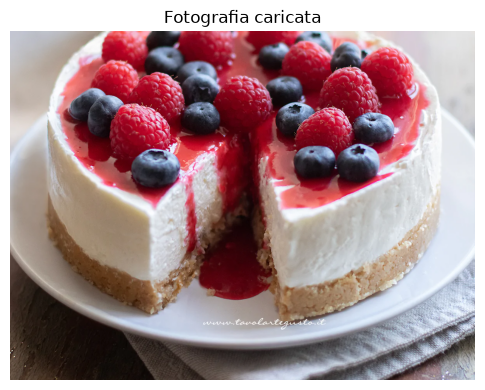

CHEFBOT AI - RICONOSCIMENTO
Piatto riconosciuto: Cheesecake
Confidenza: 96.34%

PIATTO: Cheesecake
Ingredienti: formaggio cremoso, biscotti, burro, zucchero
Porzione: 130 g
Calorie stimate: 420 kcal
Descrizione: Dessert dolce e cremoso a base di formaggio e biscotti.


In [22]:
import tkinter as tk
from tkinter import filedialog
from PIL import Image

root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

percorso_utente = filedialog.askopenfilename(
    parent=root,
    title="ChefBot AI - Seleziona una fotografia",
    filetypes=[
        ("Immagini", "*.jpg *.jpeg *.png"),
        ("Tutti i file", "*.*")
    ]
)

root.destroy()

if percorso_utente:
    with Image.open(percorso_utente) as immagine:
        plt.figure(figsize=(6, 5))
        plt.imshow(immagine.convert("RGB"))
        plt.axis("off")
        plt.title("Fotografia caricata")
        plt.show()

    riconosci_piatto(percorso_utente)
else:
    print("Nessuna fotografia selezionata.")